# Day 2 · 02 — Lab: hyperparameter optimisation, what is worth tuning (30 min)

Two experiments on NHITS, both scored on the **validation window** (the 14 weeks before the test window), so
the test set stays untouched until the final refit:

1. **One-at-a-time sensitivity.** Move one hyperparameter at a time away from the default and measure how
   much validation RMSSE moves. Big spread → worth tuning; flat → leave the default.
2. **A small Optuna search** (`AutoNHITS`, TPE sampler) over the parameters that mattered, then fANOVA
   importances from the study.

Rule of thumb for N-BEATS / N-HiTS on retail data (check it against your own results below):

| Usually worth tuning | Usually not |
|---|---|
| `input_size` (lookback) | `mlp_units` width / depth |
| `learning_rate`, `max_steps` | `n_blocks`, number of stacks |
| `scaler_type` | activation function |
| `loss` (matches the metric?) | `n_pool_kernel_size` details |

In [1]:
import logging
import warnings

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd

import bootcamp as bc

warnings.filterwarnings("ignore")
logging.getLogger("pytorch_lightning").setLevel(logging.ERROR)
logging.getLogger("lightning").setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)
palette = ["#000000", "#0072B2", "#D55E00", "#009E73", "#CC79A7", "#56B4E9", "#E69F00"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.prop_cycle": plt.cycler(color=palette)})

N_TRIALS = 8               # Optuna trials; 30+ is better if you have a GPU
# Each sensitivity fit takes ~30 s on a laptop CPU at the default size. Run these four in class (~5 min) and
# hand the others to volunteers, or set RUN_ALL = True (~12 min).
RUN_PARAMS = ["input_size", "learning_rate", "loss", "mlp_units"]
RUN_ALL = False

/home/user/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
from neuralforecast import NeuralForecast
from neuralforecast.auto import AutoNHITS
from neuralforecast.losses.pytorch import MAE, MSE, HuberLoss
from neuralforecast.models import NHITS

panel = bc.load_panel()
train, test = bc.split(panel)
fit_part, valid = bc.split(train, cutoff=bc.VALID_START)     # tune on this split only
Y_fit, Y_train = bc.to_nixtla(fit_part), bc.to_nixtla(train)
print(f"tuning fit: → {fit_part['ds'].max()} | validation: {valid['ds'].min()} → {valid['ds'].max()}")

2026-10-27 21:55:20,376	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


2026-10-27 21:55:20,921	INFO util.py:155 -- Missing packages: ['ipywidgets']. Run `pip install -U ipywidgets`, then restart the notebook server for rich notebook output.


tuning fit: → 2025-01-01 | validation: 2025-01-08 → 2025-04-09


## Intuition: tuning is a budget

Imagine a mixing desk with twenty knobs. Most change the sound very little; one or two change it a lot. The
sensitivity sweep finds out which knobs matter **before** you spend money searching over all of them. And every
gain must be compared with the noise floor from Lab 01: a knob whose effect is smaller than that is not a
finding.

## 1. One-at-a-time sensitivity

In [3]:
DEFAULT = dict(input_size=2 * bc.H, learning_rate=1e-3, scaler_type="robust", loss=MAE(),
               mlp_units=[[512, 512]] * 3, n_blocks=[1, 1, 1], max_steps=bc.MAX_STEPS)

GRID = {
    "input_size": [bc.H, 2 * bc.H, 4 * bc.H],
    "learning_rate": [1e-4, 1e-3, 5e-3],
    "scaler_type": ["identity", "standard", "robust"],
    "loss": [MAE(), MSE(), HuberLoss()],
    "max_steps": [bc.MAX_STEPS // 2, bc.MAX_STEPS, bc.MAX_STEPS * 2],
    "mlp_units": [[[128, 128]] * 3, [[512, 512]] * 3, [[1024, 1024]] * 3],
    "n_blocks": [[1, 1, 1], [2, 2, 2], [3, 3, 3]],
}


def label(v):
    return type(v).__name__ if hasattr(v, "is_distribution_output") else str(v[0][0]) + "w" if isinstance(v, list) and isinstance(v[0], list) else str(v)


_cache: dict[str, tuple[float, float]] = {}


def valid_rmsse(**overrides) -> tuple[float, float]:
    params = {**DEFAULT, **overrides}
    key = repr(sorted((k, label(v)) for k, v in params.items()))
    if key in _cache:                      # the default setting appears in every row of the grid
        return _cache[key]
    model = NHITS(h=bc.H, random_seed=bc.RANDOM_SEED, **params, **bc.trainer_kwargs())
    nf = NeuralForecast(models=[model], freq=bc.FREQ)
    with bc.Timer() as t:
        nf.fit(df=Y_fit)
    s = bc.summarise(bc.score(nf.predict(), valid, fit_part, ["NHITS"]))
    _cache[key] = (s.loc[0, "mean_rmsse"], t.seconds)
    return _cache[key]


rows = []
for param, values in GRID.items():
    if not RUN_ALL and param not in RUN_PARAMS:
        continue
    for v in values:
        score, secs = valid_rmsse(**{param: v})
        rows.append({"param": param, "value": label(v), "valid_rmsse": score, "fit_seconds": secs})
        print(f"{param:14s} {label(v):>10s}  RMSSE {score:.4f}  ({secs:.0f}s)")
sens = pd.DataFrame(rows)

input_size             14  RMSSE 1.3045  (28s)


input_size             28  RMSSE 1.2609  (28s)


input_size             56  RMSSE 1.2468  (29s)


learning_rate      0.0001  RMSSE 1.2869  (28s)
learning_rate       0.001  RMSSE 1.2609  (28s)


learning_rate       0.005  RMSSE 1.2763  (28s)
loss                  MAE  RMSSE 1.2609  (28s)


loss                  MSE  RMSSE 1.5077  (28s)


loss            HuberLoss  RMSSE 1.2600  (28s)


mlp_units            128w  RMSSE 1.2913  (7s)
mlp_units            512w  RMSSE 1.2609  (28s)


mlp_units           1024w  RMSSE 1.2543  (82s)


param
loss             0.247663
input_size       0.057733
mlp_units        0.036940
learning_rate    0.026024
Name: spread, dtype: float64

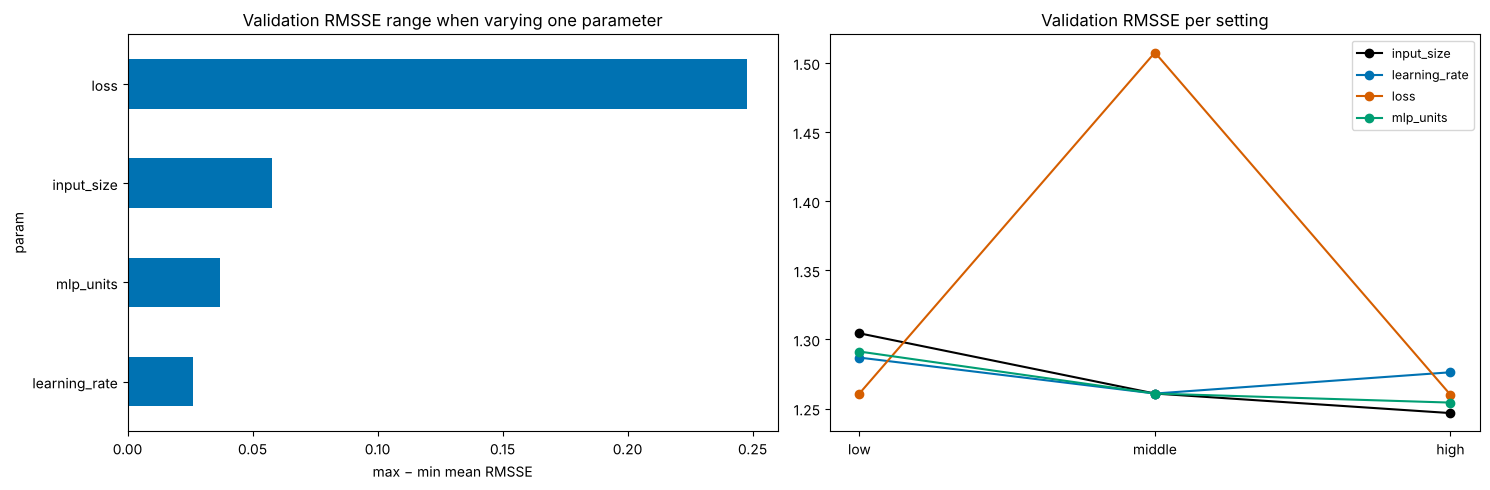

In [4]:
spread = (sens.groupby("param")["valid_rmsse"].agg(lambda s: s.max() - s.min())
          .sort_values(ascending=True).rename("spread"))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
spread.plot.barh(ax=axes[0], color=palette[1])
axes[0].set_title("Validation RMSSE range when varying one parameter")
axes[0].set_xlabel("max − min mean RMSSE")
for i, (param, g) in enumerate(sens.groupby("param")):
    axes[1].plot(range(len(g)), g["valid_rmsse"], marker="o", label=param)
axes[1].set_xticks([0, 1, 2], ["low", "middle", "high"])
axes[1].set_title("Validation RMSSE per setting")
axes[1].legend(fontsize=9)
plt.tight_layout()
spread.sort_values(ascending=False)

**Read the chart before the search.** Parameters at the bottom of the bar chart are not worth search budget:
fix them at the default. Compare the spreads with the **fold-to-fold spread from Lab 01**; a parameter whose
effect is smaller than that noise is not a finding.

### Reading the result

* In the reference run the **loss** was by far the biggest knob: validation RMSSE ≈ 1.26 with MAE or Huber,
  ≈ 1.51 with MSE. MSE squares the error, so it chases the rare promo spikes and overshoots every normal week.
* Lookback, width and learning rate each moved the score by less than 0.06.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## 2. A small Optuna search over what mattered

`AutoNHITS` with the Optuna backend uses its own internal validation split (`val_size`), here the last
14 weeks of the training data. The config function is the search space.

In [5]:
def config(trial: optuna.Trial) -> dict:
    return {
        "input_size": trial.suggest_categorical("input_size", [bc.H, 2 * bc.H, 3 * bc.H, 4 * bc.H]),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "scaler_type": trial.suggest_categorical("scaler_type", ["standard", "robust"]),
        "max_steps": trial.suggest_categorical("max_steps", [bc.MAX_STEPS, 2 * bc.MAX_STEPS]),
        "mlp_units": [[512, 512]] * 3,                 # fixed: not worth tuning
        "random_seed": bc.RANDOM_SEED,
        **bc.trainer_kwargs(),
    }


auto = AutoNHITS(h=bc.H, loss=MAE(), valid_loss=MAE(), config=config, backend="optuna",
                 search_alg=optuna.samplers.TPESampler(seed=bc.RANDOM_SEED), num_samples=N_TRIALS)
nf = NeuralForecast(models=[auto], freq=bc.FREQ)
with bc.Timer() as t_hpo:
    nf.fit(df=Y_train, val_size=bc.H)
study = nf.models[0].results
print(f"{N_TRIALS} trials in {t_hpo.seconds:.0f}s | best valid MAE {study.best_value:.3f}")
study.best_params

8 trials in 474s | best valid MAE 1383.434


{'input_size': 28,
 'learning_rate': 0.001010552166748753,
 'scaler_type': 'standard',
 'max_steps': 1000}

In [6]:
trials = study.trials_dataframe()[["number", "value", "params_input_size", "params_learning_rate",
                                   "params_scaler_type", "params_max_steps"]].sort_values("value")
try:
    importance = optuna.importance.get_param_importances(study)
    print("fANOVA importance:", {k: round(v, 3) for k, v in importance.items()})
except Exception as e:                       # needs enough completed trials
    print("importance not available:", e)
trials.head(8)

fANOVA importance: {'learning_rate': 0.966, 'input_size': 0.027, 'scaler_type': 0.007, 'max_steps': 0.0}


,number,value,params_input_size,params_learning_rate,params_scaler_type,params_max_steps
2,2,1383.433716,28,0.001011,standard,1000
6,6,1384.673462,56,0.002684,robust,500
1,1,1407.704712,42,0.006570,robust,1000
4,4,1450.593628,42,0.005463,robust,1000
5,5,1456.541016,14,0.000995,robust,500
3,3,1461.365479,14,0.000178,standard,1000
7,7,1468.727905,14,0.004732,standard,1000
0,0,1547.945923,56,0.001197,standard,1000


## 3. Refit the winner and score it on the test window

In [7]:
fcst = nf.predict().rename(columns={"AutoNHITS": "NHITS_tuned"})
bc.save_forecasts(fcst, "02_hpo")
bc.record(fcst, test, train, lab="02 HPO", fit_seconds=t_hpo.seconds,
          notes=f"{N_TRIALS} TPE trials; best {study.best_params}")
bc.leaderboard()[["model", "mean_rmsse", "median_rmsse", "wape", "fit_seconds", "lab"]]

,model,mean_rmsse,median_rmsse,wape,fit_seconds,lab
1,SEL_by_class,1.080272,0.600030,0.283513,NaN,07 ensembles
2,ENS_mean_top3,1.115220,0.581481,0.296860,NaN,07 ensembles
3,NHITSx,1.132742,0.601978,0.297665,33.792775,03 exogenous
4,ENS_median_all,1.138135,0.624758,0.331142,NaN,07 ensembles
5,NHITS_noexog,1.148003,0.630746,0.349973,31.592917,03 exogenous
6,NHITS_MQ,1.156554,0.650681,0.330773,NaN,06 uncertainty
7,LightGBM,1.168705,0.601303,0.310114,1.595912,00 day1 reference
8,NHITS_tuned,1.173963,0.647395,0.357246,474.150475,02 HPO
9,ENS_mean_all,1.178090,0.621434,0.332727,NaN,07 ensembles
10,NHITS,1.186099,0.652544,0.350907,35.010245,01 GFM default


### Reading the result

![Lab 02 results](slides/img/res_lab02.png)

* 8 Optuna trials took ≈ 474 s and moved test RMSSE from ≈ 1.186 to ≈ 1.174: **15× the compute for about 1 %**,
  and LightGBM (1.6 s, ≈ 1.169) is still ahead.
* fANOVA credits the learning rate with most of the importance, but only within the narrow range we searched.
  The one-at-a-time sweep is the more honest picture of what is worth tuning.
* Rule of thumb: get the **loss** and the **scaling** right, then stop tuning.

*Reference run: 2,000 series, laptop CPU, 500 steps. Your numbers will differ a little; the reading should not.*

## Discussion

* How much of the gain came from **one** parameter (usually the lookback)? Could you have got it with a
  three-point manual sweep instead of a search?
* The search cost N× the default fit. Compare the RMSSE gain per CPU-minute with Day 1's LightGBM.
* Tuning on a single validation window overfits that window. With more budget, score each trial with
  `cross_validation(n_windows=3)` instead.